In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from desmin_reconstruction.plotting import save_panel
from desmin_reconstruction.plotting.lineplots import line_and_bandplot
from desmin_reconstruction.utils.array import find_crossing_points
from IPython.display import display, SVG
from matplotlib.ticker import MaxNLocator


COLOR_DICT = {"desmin": "#CC3311", "actin": "#0077BB", "actinin": "#009988"}
LS_DICT = {"actin": "-.", "actinin": "-"}
LABEL_DICT = {"desmin": "Desmin", "actin": "Actin", "actinin": "α-actinin"}

/tmp/ipykernel_3749069/1663192001.py:24: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f"Median: {float(r_median):.1f}nm",


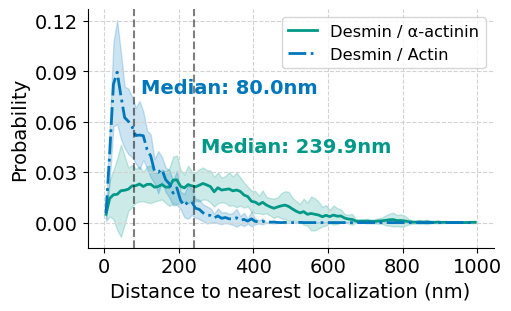

In [2]:
plt.rc("font", size=14)
fig, ax = plt.subplots(1, 1, figsize=(5, 3), constrained_layout=True)
for protein in ("actinin", "actin"):
    df = pl.read_csv(f"../../source_data/fig_3/3c_{protein}.csv")
    x, y, y_err = df["x"].to_numpy(), df["y"].to_numpy(), df["y_error"].to_numpy()
    ax = line_and_bandplot(
        ax,
        x,
        y,
        y_err,
        color=COLOR_DICT[protein],
        linestyle=LS_DICT[protein],
        label=f"Desmin / {LABEL_DICT[protein]}",
        linewidth=2.0,
        alpha=1.0,
        alpha_band=0.2,
    )
    r_median, idx_cross = find_crossing_points(x, np.cumsum(y), 0.5)

    ax.axvline(r_median, ls="--", color="k", alpha=0.5)
    ax.text(
        r_median + 20,
        y[idx_cross] + 0.02,
        f"Median: {float(r_median):.1f}nm",
        color=COLOR_DICT[protein],
        weight="bold",
    )
ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(ls="--", color="lightgray")
ax.set_xlabel("Distance to nearest localization (nm)")
ax.set_ylabel("Probability")
ax.legend(fontsize="small", handlelength=1.8)
# fig.savefig("../figures/fig_3/3c.svg", dpi=500, bbox_inches="tight")

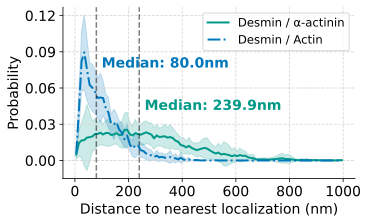

In [3]:
savepath = "../../figures/3c"
save_panel(fig, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig)